# Factors associated with video game success

## Goal
Identify the factors associated with game success.
Identify a potentially successful product and use it to recommend where to focus marketing campaigns.

## Analysis plan
Data overview

Data preparation

Exploratory data analysis

User profile for each region

Hypothesis testing

In [1]:
# import the libraries needed for the analysis: pandas, matplotlib, seaborn, scipy, numpy
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats as st
import numpy as np

In [2]:
# read the csv file
data = pd.read_csv('/datasets/games.csv')

## Data preparation

In [3]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 16715 entries, 0 to 16714
Data columns (total 11 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   Name             16713 non-null  object 
 1   Platform         16715 non-null  object 
 2   Year_of_Release  16446 non-null  float64
 3   Genre            16713 non-null  object 
 4   NA_sales         16715 non-null  float64
 5   EU_sales         16715 non-null  float64
 6   JP_sales         16715 non-null  float64
 7   Other_sales      16715 non-null  float64
 8   Critic_Score     8137 non-null   float64
 9   User_Score       10014 non-null  object 
 10  Rating           9949 non-null   object 
dtypes: float64(6), object(5)
memory usage: 1.4+ MB


### Column names

In [4]:
# Lower-case the column names
data.columns = data.columns.str.lower()

In [5]:
data.head()

,name,platform,year_of_release,genre,na_sales,eu_sales,jp_sales,other_sales,critic_score,user_score,rating
0,Wii Sports,Wii,2006.0,Sports,41.36,28.96,3.77,8.45,76.0,8,E
1,Super Mario Bros.,NES,1985.0,Platform,29.08,3.58,6.81,0.77,NaN,NaN,NaN
2,Mario Kart Wii,Wii,2008.0,Racing,15.68,12.76,3.79,3.29,82.0,8.3,E
3,Wii Sports Resort,Wii,2009.0,Sports,15.61,10.93,3.28,2.95,80.0,8,E
4,Pokemon Red/Pokemon Blue,GB,1996.0,Role-Playing,11.27,8.89,10.22,1.00,NaN,NaN,NaN


### Data types
Two columns need type conversion: year_of_release and user_score.
The conversion is possible only after the missing values are handled.

### Missing values

In [6]:
 # count missing values per column
print(data.isna().sum())

name                  2
platform              0
year_of_release     269
genre                 2
na_sales              0
eu_sales              0
jp_sales              0
other_sales           0
critic_score       8578
user_score         6701
rating             6766
dtype: int64


In [7]:
# to decide how to handle missing values, compute their share per column
pd.DataFrame(round(data.isna().mean()*100,1)).style.background_gradient('coolwarm')

,0
name,0.000000
platform,0.000000
year_of_release,1.600000
genre,0.000000
na_sales,0.000000
eu_sales,0.000000
jp_sales,0.000000
other_sales,0.000000
critic_score,51.300000
user_score,40.100000


Missing values were found in: year_of_release, critic_score, user_score, rating.
The share of missing values in year_of_release is small, so these rows were dropped.
Dropping rows with missing values in the other columns would not be appropriate because the share is large. Imputing the median is also inappropriate, because critic scores, user scores and ratings vary a lot from game to game.
Missing critic_score values were left unchanged.
Missing rating values were filled with 'unknown'.

user_score also contains the value 'tbd' ('to be determined'): the score is not yet available and may be added later. These values were replaced with np.nan.


In [8]:
# drop rows with missing year_of_release
data = data.dropna(subset=['year_of_release'])

In [9]:
# handle 'tbd' values
data['user_score'] = data['user_score'].replace ('tbd', np.nan)

In [10]:
# handle missing values in rating
data['rating'] = data['rating']. fillna('Unknown')

Possible reasons for the missing values: users do not always rate games, not every game is reviewed by critics or rated by the ESRB.
Technical errors during data export are also possible.

### Data types (continued)

In [11]:
data['year_of_release'] = data['year_of_release'].astype('int')

In [12]:
data['user_score'] = data['user_score'].astype('float')

### Total sales across all regions

In [13]:
data['sales_total'] = data['na_sales']+data['eu_sales']+data['jp_sales']+data['other_sales']

### Duplicates

In [14]:
# search for exact duplicates
data.duplicated().sum()

0

## Exploratory data analysis

### Number of games released per year

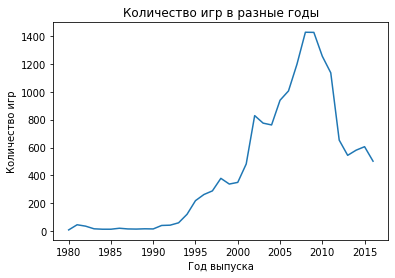

In [15]:
games_per_year = data.pivot_table (index='year_of_release', values='name', aggfunc='count').plot(legend=False,)
plt.title ('Number of games released per year')
plt.ylabel ('Number of games')
plt.xlabel ('Release year');

Far more games were released after 2000 than before, with a peak in 2008-2010.

### Sales by platform over time

In [16]:
# platforms with the highest total sales (top 10)
sales_per_platform_max = data.pivot_table(index= 'platform', values='sales_total', aggfunc='sum').sort_values(by='sales_total', ascending=False).head(10)
display (sales_per_platform_max)

,sales_total
platform,
PS2,1233.56
X360,961.24
PS3,931.34
Wii,891.18
DS,802.78
PS,727.58
PS4,314.14
GBA,312.88
PSP,289.53


In [17]:
# names of the platforms with the highest total sales
top_pl = sales_per_platform_max .index
print(top_pl)

Index(['PS2', 'X360', 'PS3', 'Wii', 'DS', 'PS', 'PS4', 'GBA', 'PSP', '3DS'], dtype='object', name='platform')


In [18]:
# filter the dataset to the top-selling platforms
games = data[data['platform'].isin(top_pl)]

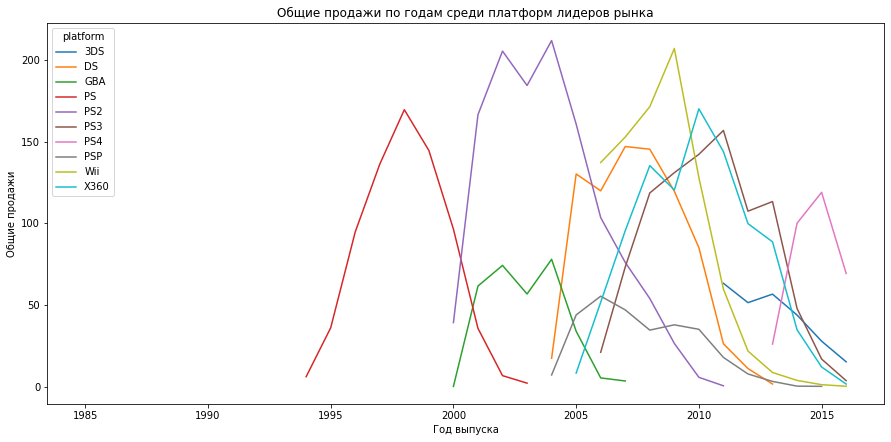

In [19]:
# plot yearly sales for the top-selling platforms
games .pivot_table(index = 'year_of_release', columns = 'platform', aggfunc = 'sum', values = 'sales_total').plot(figsize = (15,7));
plt.title ('Total sales by year for the market-leading platforms')
plt.ylabel ('Total sales')
plt.xlabel ('Release year');

On average a platform stays active for 5-10 years and is then replaced by a new one.

### Defining the relevant period

For the rest of the analysis the relevant period is defined as 2014-2016.

### Identifying potentially profitable platforms

In [20]:
# total sales by platform for the relevant period (2014-2016)
platforms_actual = data.query('year_of_release>=2014').pivot_table(index='platform', values='sales_total', aggfunc='sum').sort_values(by='sales_total', ascending=False)
display(platforms_actual)

,sales_total
platform,
PS4,288.15
XOne,140.36
3DS,86.68
PS3,68.18
X360,48.22
WiiU,42.98
PC,27.05
PSV,22.40
Wii,5.07


In [21]:
# platform names for the relevant period
actual_pl = platforms_actual .index
print(actual_pl)

Index(['PS4', 'XOne', '3DS', 'PS3', 'X360', 'WiiU', 'PC', 'PSV', 'Wii', 'PSP'], dtype='object', name='platform')


In [22]:
# filter the dataset by platform for the relevant period
data_actual_pre= data[data['platform'].isin(actual_pl)]
data_actual=data_actual_pre.query('year_of_release>=2014')

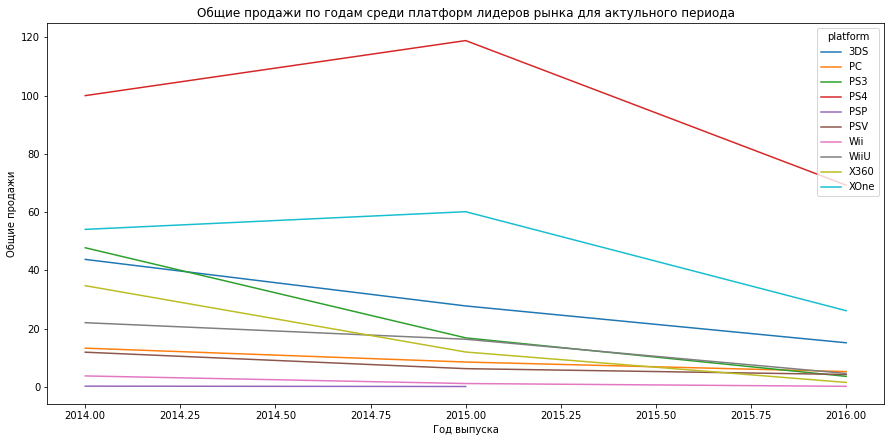

In [23]:
# plot yearly sales for the top-selling platforms
data_actual .pivot_table(index = 'year_of_release', columns = 'platform', aggfunc = 'sum', values = 'sales_total').plot(figsize = (15,7));
plt.title ('Total sales by year for the leading platforms, relevant period')
plt.ylabel ('Total sales')
plt.xlabel ('Release year');



In the relevant period, the platforms with the highest sales at the start (Wii, X360, PS3) are almost gone by 2016.

PS4 and XOne are the potentially profitable platforms.

### Global sales by platform

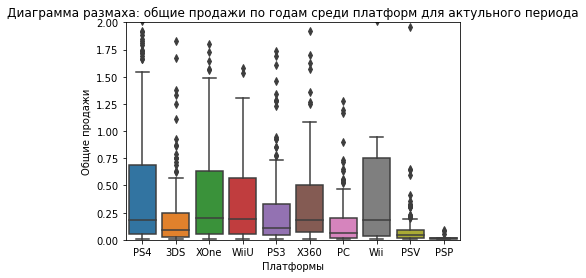

In [24]:
sns.boxplot(data = data_actual, x = 'platform', y = 'sales_total');
plt.ylim(0, 2)
plt.title ('Box plot: total sales by platform, relevant period')
plt.ylabel ('Total sales')
plt.xlabel ('Platform');


By both total and median sales, the leading platforms are X360, PS4, XOne, WiiU and Wii.

### Correlation between reviews (critics and users) and total sales for the market leader (PS4)

In [25]:
# slice the data to one of the leading platforms of the period
data_actual_for_ps4= data_actual.query('platform == "PS4"')

In [26]:
# Pearson correlation between critic score and total sales
print('Critic score vs total sales', data_actual_for_ps4.loc[~data_actual_for_ps4['critic_score'].isnull(), 'sales_total'].corr(data_actual_for_ps4.loc[~data_actual_for_ps4['critic_score'].isnull(), 'critic_score']))


Оценка критиков-общие продажи 0.40266141068104083


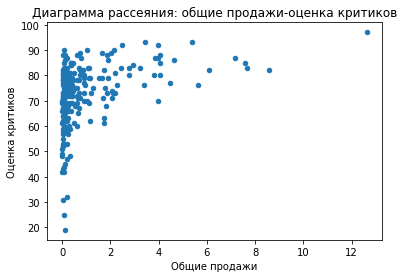

In [27]:
# plot the result
data_actual_for_ps4.plot(x='sales_total', y='critic_score', kind='scatter')
plt.title ('Scatter plot: total sales vs critic score')
plt.ylabel ('Critic score')
plt.xlabel ('Total sales');

In [28]:
# correlation between user score and total sales
print('User score vs total sales', data_actual_for_ps4.loc[~data_actual_for_ps4['user_score'].isnull(), 'sales_total'].corr(data_actual_for_ps4.loc[~data_actual_for_ps4['user_score'].isnull(), 'user_score']))

Оценка игроков-общие продажи -0.040131589472697356


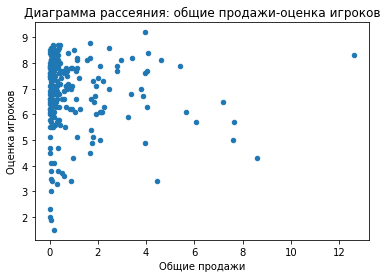

In [29]:
data_actual_for_ps4.plot(x='sales_total', y='user_score', kind='scatter')
plt.title ('Scatter plot: total sales vs user score')
plt.ylabel ('User score')
plt.xlabel ('Total sales');

For one platform (PS3) there is no strong relationship between scores and total sales, but critic scores are more related to sales than user scores (the positive correlation is stronger, Pearson coefficient closer to 1).

### Correlation for the other platforms

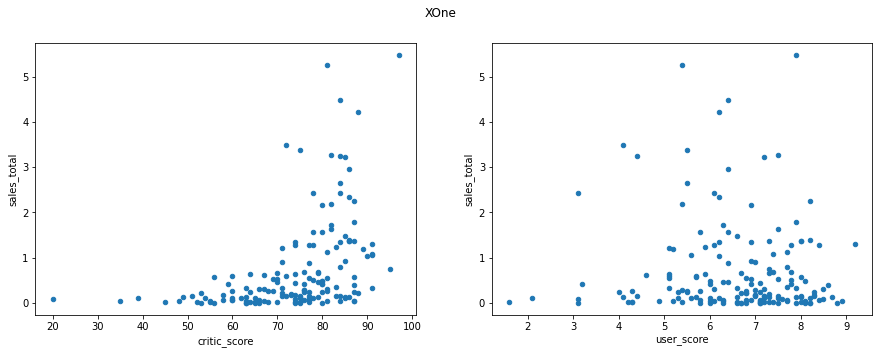

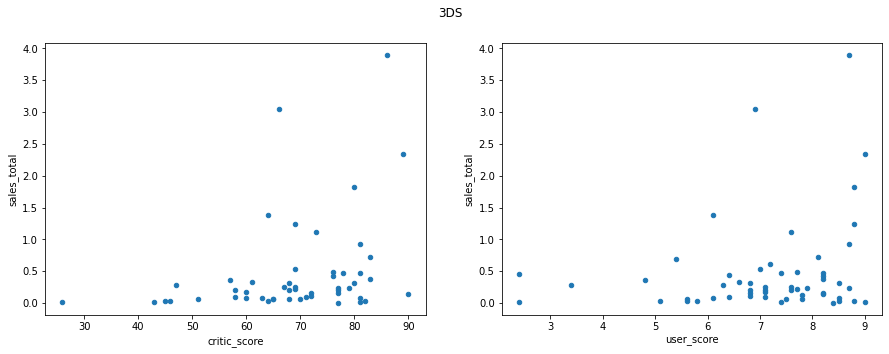

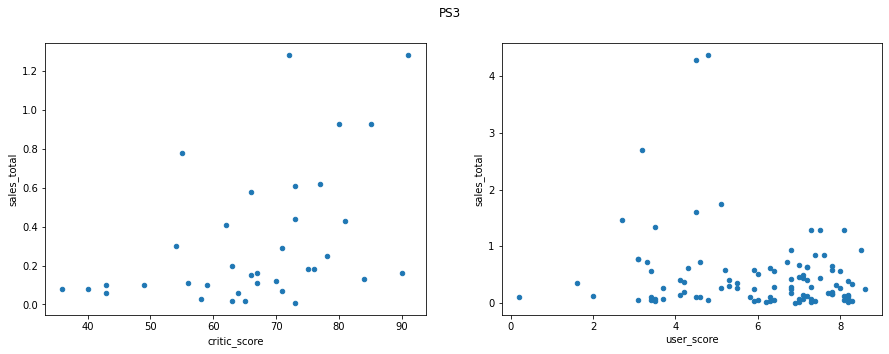

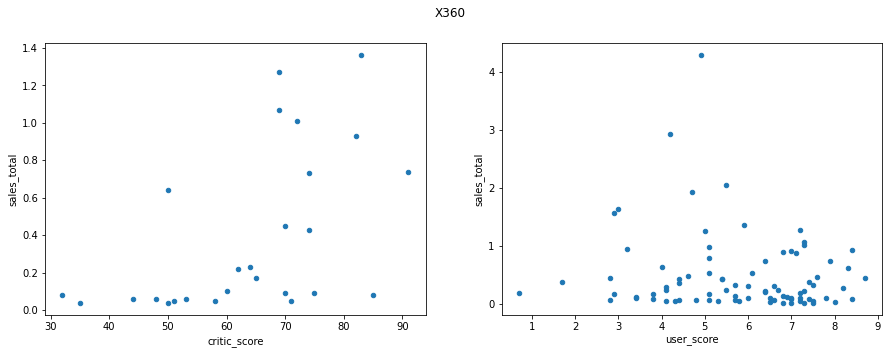

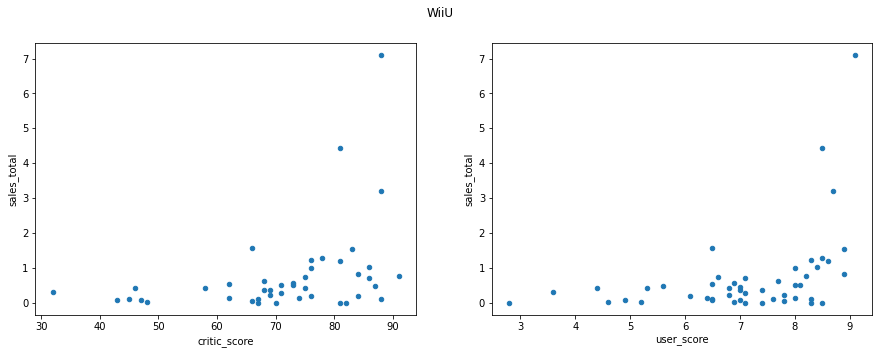

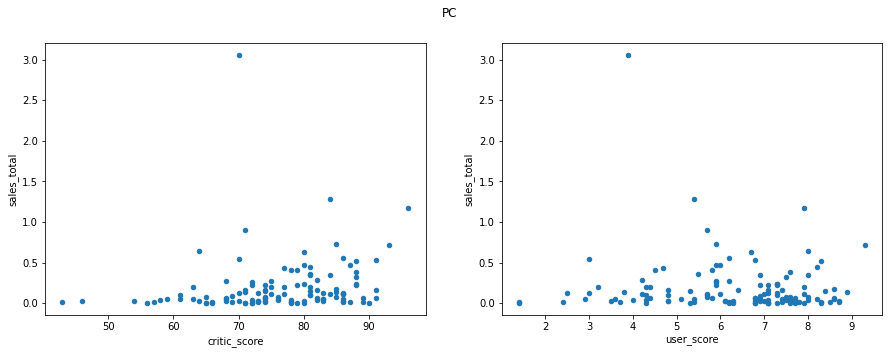

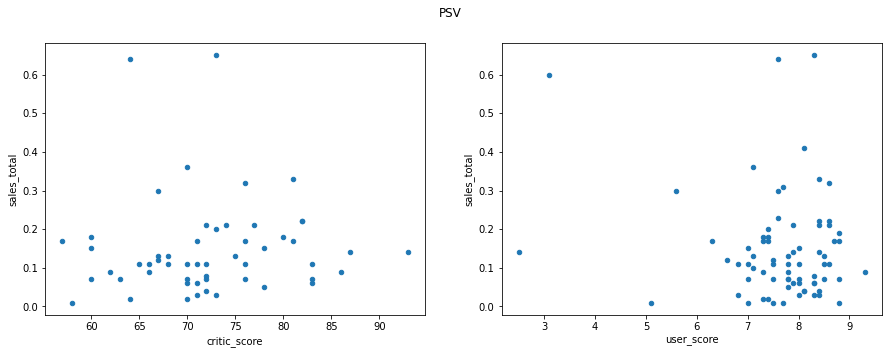

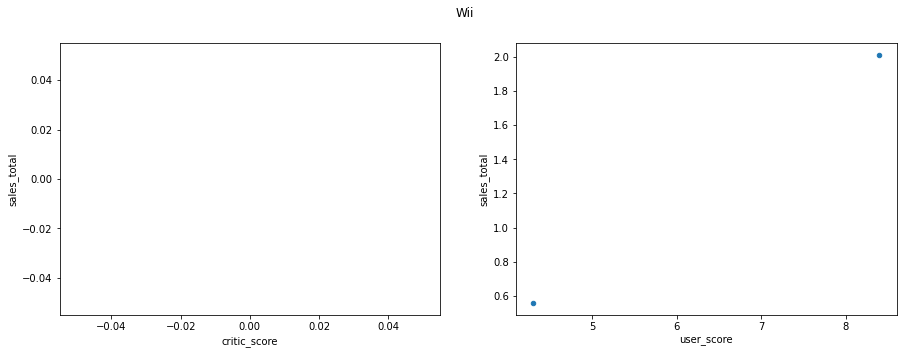

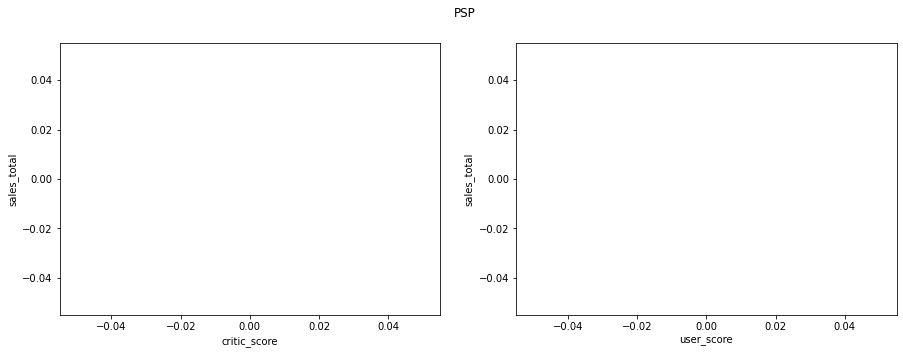

In [30]:
for pl in ['XOne', '3DS', 'PS3', 'X360', 'WiiU', 'PC', 'PSV', 'Wii', 'PSP']:
    fig, ax = plt.subplots(1,2, figsize = (15,5))
    ax = ax.ravel()
    data_actual.query('platform == @pl').plot(kind='scatter', x='critic_score', y='sales_total', ax = ax[0])
    data_actual.query('user_score != "tbd" and user_score != -10 and platform == @pl').plot(kind='scatter', x='user_score', y='sales_total', ax = ax[1])
    fig.suptitle(pl)

The charts show no clear correlation between user or critic scores and total sales for the other platforms of the relevant period either.

In [31]:
platforms = ['PS4', 'XOne', '3DS', 'PS3', 'X360', 'WiiU', 'PC', 'PSV', 'Wii', 'PSP']
for pl in platforms:
    print(pl)
    print( 'User score vs total sales', data_actual.query ('platform ==@pl and critic_score != "nan"')['sales_total'].corr(data_actual.query ('platform ==@pl')['user_score']))
    print('Critic score vs total sales', data_actual.query ('platform ==@pl')['sales_total'].corr(data_actual.query ('platform ==@pl')['critic_score']))

PS4
Оценка игроков-общие продажи -0.040131589472697356
Оценка критиков-общие продажи 0.40266141068104083
XOne
Оценка игроков-общие продажи -0.0703839280647581
Оценка критиков-общие продажи 0.42867694370333226
3DS
Оценка игроков-общие продажи 0.2151932718527028
Оценка критиков-общие продажи 0.31411749286905105
PS3
Оценка игроков-общие продажи -0.16676141347662116
Оценка критиков-общие продажи 0.44657460493190704
X360
Оценка игроков-общие продажи -0.138444570945665
Оценка критиков-общие продажи 0.5257228356581523
WiiU
Оценка игроков-общие продажи 0.4079264579217078
Оценка критиков-общие продажи 0.370201412480884
PC
Оценка игроков-общие продажи -0.07159665703472452
Оценка критиков-общие продажи 0.17463413769350036
PSV
Оценка игроков-общие продажи -0.16845504978064446
Оценка критиков-общие продажи 0.04266490657009526
Wii
Оценка игроков-общие продажи 1.0
Оценка критиков-общие продажи nan
PSP
Оценка игроков-общие продажи nan
Оценка критиков-общие продажи nan


For the other platforms, too, critic scores are more related to sales than user scores.

### Distribution of games by genre

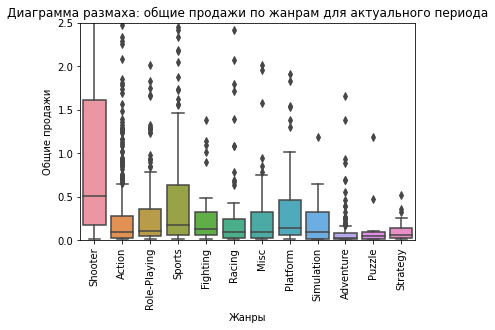

In [32]:
sns.boxplot(data = data_actual, x = 'genre', y = 'sales_total');
plt.ylim(0, 2.5)
plt.title ('Box plot: total sales by genre, relevant period')
plt.ylabel ('Total sales')
plt.xlabel ('Genre')
plt.xticks(rotation=90);


By median sales the most profitable genre is Shooter.

The genre with the lowest median sales is Adventure.

## User profile by region

### Most popular platforms in North America (top 5)

In [33]:
platforms_in_na = data_actual.pivot_table (index='platform', values='na_sales', aggfunc='sum'). sort_values(by='na_sales', ascending=False)
platforms_in_na.head()

,na_sales
platform,
PS4,98.61
XOne,81.27
X360,28.30
3DS,22.64
PS3,22.05


In [34]:
# combine platforms outside the top 5 into 'others' and sum their sales
platforms_in_na.loc['Other', 'na_sales'] = platforms_in_na.iloc[5:].sum()[0]
display(platforms_in_na)

,na_sales
platform,
PS4,98.61
XOne,81.27
X360,28.30
3DS,22.64
PS3,22.05
WiiU,19.36
PC,7.23
PSV,2.52
Wii,2.08


In [35]:
print(len(platforms_in_na))

11


In [36]:
# keep only the top 5 and others
platforms_in_na = platforms_in_na.iloc [[0,1, 2, 3, 4, 10]]

In [37]:
display(platforms_in_na)

,na_sales
platform,
PS4,98.61
XOne,81.27
X360,28.30
3DS,22.64
PS3,22.05
Other,31.19


In [38]:
# total platform sales in the region
platforms_in_na['na_sales']. sum ().round(0)

284.0

In [39]:
# share of the top 5 platforms and others in regional sales
platforms_in_na['percent_sales'] = (platforms_in_na['na_sales']/284.0*100).round(0)

In [40]:
display(platforms_in_na)

,na_sales,percent_sales
platform,,
PS4,98.61,35.0
XOne,81.27,29.0
X360,28.30,10.0
3DS,22.64,8.0
PS3,22.05,8.0
Other,31.19,11.0


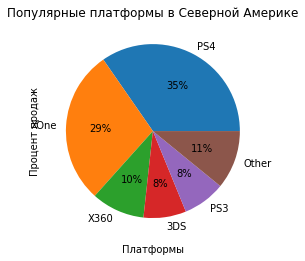

In [42]:
# plot the result
platforms_in_na.plot(kind='pie',y='percent_sales', legend=False, figsize=(4,4), autopct='%.0f%%')
plt.title ('Popular platforms in North America')
plt.ylabel ('Share of sales, %')
plt.xlabel ('Platform');

### Most popular platforms in Europe (top 5)

In [43]:
platforms_in_eu = data_actual.pivot_table (index='platform', values='eu_sales', aggfunc='sum'). sort_values(by='eu_sales', ascending=False)
platforms_in_eu.head()

,eu_sales
platform,
PS4,130.04
XOne,46.25
PS3,25.54
PC,17.97
3DS,16.12


In [44]:
# combine platforms outside the top 5 into 'others' and sum their sales
platforms_in_eu.loc['Other', 'eu_sales'] = platforms_in_eu.iloc[5:].sum()[0]
display(platforms_in_eu)

,eu_sales
platform,
PS4,130.04
XOne,46.25
PS3,25.54
PC,17.97
3DS,16.12
X360,15.49
WiiU,13.15
PSV,3.53
Wii,2.59


In [45]:
print(len(platforms_in_eu))

11


In [46]:
# keep only the top 5 and others
platforms_in_eu = platforms_in_eu.iloc [[0,1, 2, 3, 4, 10]]
display(platforms_in_eu)

,eu_sales
platform,
PS4,130.04
XOne,46.25
PS3,25.54
PC,17.97
3DS,16.12
Other,34.76


In [47]:
# total platform sales in the region
platforms_in_eu['eu_sales']. sum ().round(0)

271.0

In [48]:
# share of each platform in regional sales
platforms_in_eu['percent_sales'] = (platforms_in_eu['eu_sales']/271.0*100).round(0)

In [49]:
display(platforms_in_eu)

,eu_sales,percent_sales
platform,,
PS4,130.04,48.0
XOne,46.25,17.0
PS3,25.54,9.0
PC,17.97,7.0
3DS,16.12,6.0
Other,34.76,13.0


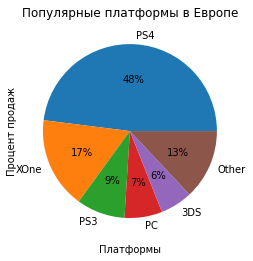

In [50]:
# plot the result
platforms_in_eu.plot(kind='pie',y='percent_sales', legend=False, figsize=(4,4), autopct='%.0f%%')
plt.title ('Popular platforms in Europe')
plt.ylabel ('Share of sales, %')
plt.xlabel ('Platform');

### Most popular platforms in Japan (top 5)

In [51]:
platforms_in_jp = data_actual.pivot_table (index='platform', values='jp_sales', aggfunc='sum'). sort_values(by='jp_sales', ascending=False)
platforms_in_jp.head()

,jp_sales
platform,
3DS,44.24
PS4,15.02
PSV,14.54
PS3,11.22
WiiU,7.31


In [52]:
# combine platforms outside the top 5 into 'others' and sum their sales
platforms_in_jp.loc['Other', 'jp_sales'] = platforms_in_jp.iloc[5:].sum()[0]
display(platforms_in_jp)

,jp_sales
platform,
3DS,44.24
PS4,15.02
PSV,14.54
PS3,11.22
WiiU,7.31
PSP,0.36
XOne,0.32
X360,0.08
PC,0.00


In [53]:
# keep only the top 5 and others
platforms_in_jp = platforms_in_jp.iloc [[0,1, 2, 3, 4, 10]]
display(platforms_in_jp)

,jp_sales
platform,
3DS,44.24
PS4,15.02
PSV,14.54
PS3,11.22
WiiU,7.31
Other,0.76


In [54]:
# total platform sales in the region
platforms_in_jp['jp_sales']. sum ().round(0)

93.0

In [55]:
# share of each platform in regional sales
platforms_in_jp['percent_sales'] = (platforms_in_jp['jp_sales']/93.0*100).round(0)

In [56]:
display(platforms_in_jp)

,jp_sales,percent_sales
platform,,
3DS,44.24,48.0
PS4,15.02,16.0
PSV,14.54,16.0
PS3,11.22,12.0
WiiU,7.31,8.0
Other,0.76,1.0


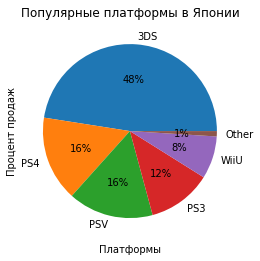

In [57]:
# plot the result
platforms_in_jp.plot(kind='pie',y='percent_sales', legend=False, figsize=(4,4), autopct='%.0f%%')
plt.title ('Popular platforms in Japan')
plt.ylabel ('Share of sales, %')
plt.xlabel ('Platform');

The market leaders differ by region. Each region has a clear leader:

North America: PS4 (35%) and XOne (29%)

Europe: PS3 (48%)

Japan: 3DS (48%)

PS3 is in the top 5 in every region.

Some platforms are not present in every region: XOne is popular in North America and Europe but is not in Japan's top 5.


### Most popular genres in North America (top 5)

In [58]:
genres_in_na = data_actual.pivot_table (index='genre', values='na_sales', aggfunc='sum'). sort_values(by='na_sales', ascending=False)
genres_in_na.head()

,na_sales
genre,
Shooter,79.02
Action,72.53
Sports,46.13
Role-Playing,33.47
Misc,15.05


### Most popular genres in Europe (top 5)

In [59]:
genres_in_eu = data_actual.pivot_table (index='genre', values='eu_sales', aggfunc='sum'). sort_values(by='eu_sales', ascending=False)
genres_in_eu.head()

,eu_sales
genre,
Action,74.68
Shooter,65.52
Sports,45.73
Role-Playing,28.17
Racing,14.13


### Most popular genres in Japan (top 5)

In [60]:
genres_in_jp = data_actual.pivot_table (index='genre', values='jp_sales', aggfunc='sum'). sort_values(by='jp_sales', ascending=False)
genres_in_jp.head()

,jp_sales
genre,
Role-Playing,31.16
Action,29.58
Fighting,6.37
Misc,5.61
Shooter,4.87


North America and Europe largely share the same popular genres, while genre popularity in Japan is distributed differently.

## Effect of ESRB rating on sales by region

In [61]:
rating_in_na = data_actual.pivot_table (index='rating', values='na_sales', aggfunc='sum'). sort_values(by='na_sales', ascending=False)
display(rating_in_na)

,na_sales
rating,
M,96.42
Unknown,64.72
E,50.74
T,38.95
E10+,33.23


In [62]:
rating_in_eu = data_actual.pivot_table (index='rating', values='eu_sales', aggfunc='sum'). sort_values(by='eu_sales', ascending=False)
display(rating_in_eu)

,eu_sales
rating,
M,93.44
Unknown,58.95
E,58.06
T,34.07
E10+,26.16


In [63]:
rating_in_jp = data_actual.pivot_table (index='rating', values='jp_sales', aggfunc='sum'). sort_values(by='jp_sales', ascending=False)
display(rating_in_jp)

,jp_sales
rating,
Unknown,56.90
T,14.78
E,8.94
M,8.01
E10+,4.46


The relationship between ESRB rating and total sales differs strongly by region.

In Japan most games sold have no ESRB rating, probably because the rating is not mandatory there and is not always obtained.

In Europe and North America most games sold are rated M (Mature, 17+).

## Hypothesis testing

Hypotheses

H0: the average user ratings of the Xbox One and PC platforms are equal

H1: the average user ratings of the Xbox One and PC platforms are not equal

In [64]:
sample_1 = data_actual.loc[(data_actual['platform'] == 'XOne') & ~data_actual['user_score'].isnull()]['user_score']
                           
sample_2 = data_actual.loc[(data_actual['platform'] == 'PC') & ~data_actual['user_score'].isnull()]['user_score']
alpha = 0.05 # significance level
# if the p-value is below it, reject the null hypothesis

results = st.ttest_ind(sample_1, sample_2)

print('p-value:', results.pvalue)

if results.pvalue < alpha:
    print('Reject the null hypothesis')
else:
    print('Failed to reject the null hypothesis') 

p-значение: 0.10450507919348415
Не получилось отвергнуть нулевую гипотезу


Average user ratings of the Action and Sports genres differ.

H0: the average user ratings of the Action and Sports genres are equal.

H1: the average user ratings of the Action and Sports genres are not equal.

In [65]:
sample_1 = data_actual.loc[(data_actual['genre'] == 'Action') & ~data_actual['user_score'].isnull()]['user_score']
                           
sample_2 = data_actual.loc[(data_actual['genre'] == 'Sports') & ~data_actual['user_score'].isnull()]['user_score']

alpha = 0.05 # significance level
# if the p-value is below it, reject the null hypothesis

results = st.ttest_ind(sample_1, sample_2)

print('p-value:', results.pvalue)

if results.pvalue < alpha:
    print('Reject the null hypothesis')
else:
    print('Failed to reject the null hypothesis') 

p-значение: 2.8711147985105864e-19
Отвергаем нулевую гипотезу


## CONCLUSIONS

### Goal

Identify the factors associated with game success. Identify a potentially successful product and use it to recommend where to focus marketing campaigns.

### Analysis

#### Data preparation

Missing values were identified and handled, a total-sales column was added, and column names were lower-cased.


#### Exploratory data analysis

Far more games were released after 2000 than before, with a peak in 2008-2010.

On average a platform stays active for 5-10 years.

The relevant period was defined as 2014-2016.

In that period, the platforms with the highest sales at the start (Wii, X360, PS3) are almost gone by 2016.

PS4 and XOne are the potentially profitable platforms.

By median sales the leading platforms are X360, PS4, XOne, WiiU and Wii.

For one platform (PS3) there is no strong relationship between scores and total sales, but critic scores are more related to sales than user scores.




#### User profile by region

The market leaders differ by region, each with a clear leader:

North America: PS4 (35%) and XOne (29%)

Europe: PS3 (48%)

Japan: 3DS (48%)

PS3 is in the top 5 in every region.

Some platforms are not present in every region: XOne is popular in North America and Europe but is not in Japan's top 5.

North America and Europe largely share the same popular genres, while Japan differs.


The relationship between ESRB rating and sales differs strongly by region.

In Japan most games sold have no ESRB rating, probably because the rating is not mandatory there.

In Europe and North America most games sold are rated M (Mature, 17+).


#### Hypothesis testing
Statistical tests showed:

Average user ratings of Xbox One and PC are equal (no evidence of a difference).

Average user ratings of the Action and Sports genres are not equal.



### Recommendations

Product development and marketing campaigns should take the target region into account.

In North America and Europe the most popular genres are Action and Shooter; in Japan, Role-Playing and Action.

PS4 and XOne are the potentially profitable platforms.
